# Machine Learning Lab - Learning Unit 3
## Domain Translation between T1- and T2-weighted Magnetic Resonance Images using U-Net

Magnetic resonance imaging makes it possible to generate images of the same tissue with different grey scale values. With T1 weighting, fatty body tissue and structures are displayed with a higher intensity than the surrounding tissue, while with T2 weighting, fluid-filled body structures are displayed with hyperintensity. Depending on the examination, one or the other weighting can be useful; often only their combination provides the full range of required information.

In this notebook we want to train a U-Net that receives **T1-weighted brain scans as input** and **generates the corresponding T2-weighted images as output**. Corresponding image pairs are given for training and testing. To load the data, we provide you with the `BrainsDataset` class (see below). With the parameter `mode` you can switch between training and test data. `mode=train` will load the training data and `mode=test` the test data. Default value is `train`.

The U-Net is the most commonly used convolutional network architecture for image processing tasks. The original paper can be found here: https://arxiv.org/abs/1505.04597. Further interesting reads are:


*   https://paperswithcode.com/method/u-net
*   https://medium.datadriveninvestor.com/an-overview-on-u-net-architecture-d6caabf7caa4
  



In [5]:
#imports
import warnings
warnings.filterwarnings("ignore")

from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import Compose
from torch.utils.data.sampler import SubsetRandomSampler
import torch.nn.functional as F
import torch.nn as nn
import torch

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
from tqdm import tqdm_notebook as tqdm

import requests
import sys
import os
import glob
import skimage.io as io
from imageio import imread
from io import BytesIO
from zipfile import ZipFile

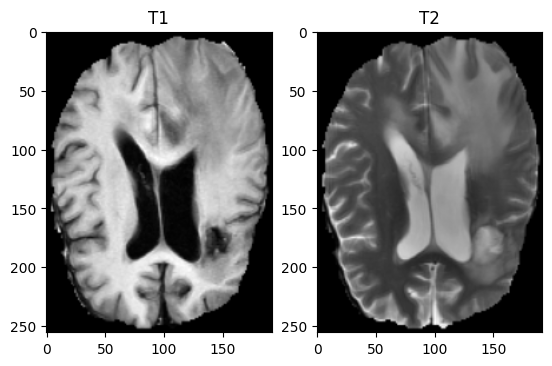

In [6]:
class BrainsDataset(Dataset):
    ''' T1-T2 image pairs dataset '''

    def __init__(self, mode="train"):

        self.t1_images = []
        self.t2_images = []

        # Load data from cloud
        #url = 'https://cloud.imi.uni-luebeck.de/s/2MdmDjnbfRFcP3g/download?path=/&files=' + mode + '.zip'
        url = 'https://cloud.imi.uni-luebeck.de/s/'
        url += 'xLycZz7z7GXCRNs' if mode=='train' else 'g7JoB3if8di4rLx'
        url += '/download'
        r = requests.get(url)
        z = ZipFile(BytesIO(r.content))

        t1_list = [name for name in z.namelist() if mode + '/t1' in name]
        t2_list = []

        for t1_name in t1_list:
            t2_name = t1_name.replace('/t1', '/t2').replace('_t1', '_t2')

            if t2_name in z.namelist():
                t1_image = imread(z.open(t1_name))
                t2_image = imread(z.open(t2_name))
                self.t1_images.append(t1_image)
                self.t2_images.append(t2_image)
                t2_list.append(t2_name)
            else:
                continue

        self.t2_list = t2_list

    def __len__(self):
        return len(self.t2_list)

    def __getitem__(self, index):
        image_t1 = self.t1_images[index]/255.
        image_t2 = self.t2_images[index]/255.

        image_t1 = torch.tensor(image_t1).float()
        image_t2 = torch.tensor(image_t2).float()

        image_t1 = F.interpolate(image_t1.unsqueeze(0).unsqueeze(0), (256, 192), mode='bilinear').squeeze(0)
        image_t2 = F.interpolate(image_t2.unsqueeze(0).unsqueeze(0), (256, 192), mode='bilinear').squeeze(0)
        return {"t1":image_t1 , "t2":image_t2}

# Initialize dataset
dataset = BrainsDataset()

# Plot T1- and T2-weighted images for one patient
fig, ax = plt.subplots(1, 2)
ax[0].imshow(dataset.__getitem__(46)['t1'].numpy()[0,:], cmap='gray')
ax[0].title.set_text('T1')
ax[1].imshow(dataset.__getitem__(46)['t2'].numpy()[0,:], cmap='gray');
ax[1].title.set_text('T2')


*   The sample pair shows exactly the contrast change the network has to learn. In T1 image the fluid filled venricles are dark. In T2 they are brighter. The grey whote matter contrast is inverted as well.
*   The two slices are spatially aligend. All images are scaled to [0,1], have one channel and are resized to 256 x 192.

  The data forms clean, paired image pairs, so image-to-image regression with a pixel-wise loss is a suitable setup.




## Task 1
Complete the **2D U-Net**.  The architecture used should correspond to the following:



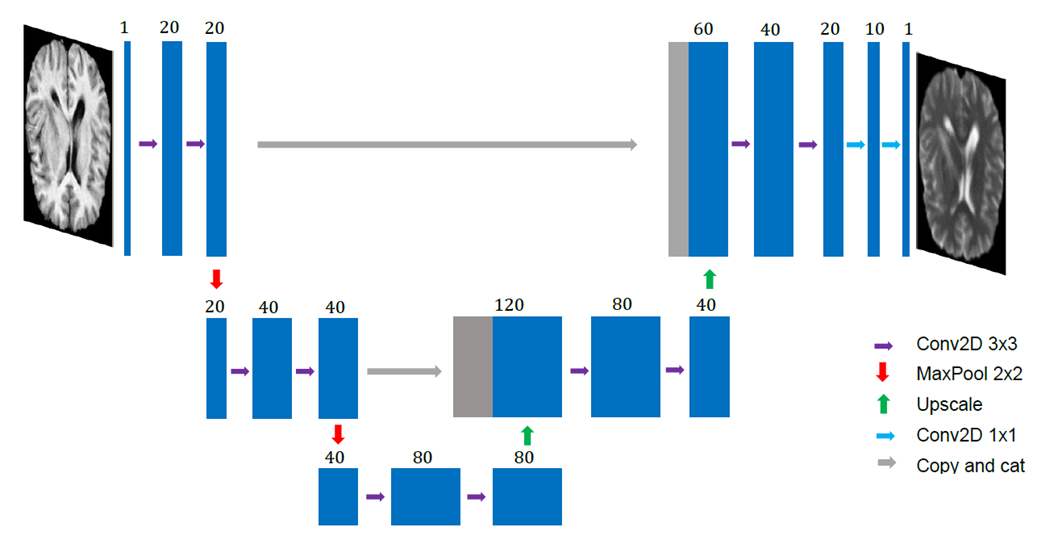

The numbers above the blue boxes indicate the number of feature maps. Red arrows signify maximum pooling with kernel size 2x2 and stride 2. For convolutional layers with kernel size 3x3 use `padding=1`. Each 3x3-convolution should be followed by batch normalization and ReLU activation. For upscaling you can try different interpolation methods (nearest, bilinear). Gray arrows stand for skip connections, the decisive difference of U-Net compared to other CNN architectures.

In [11]:
class UNet(nn.Module):
    def __init__(self):
        super().__init__()

        # To do: Implement convolutional blocks
        # Encoder Blocks
        self.block0 = nn.Sequential( # Input 1, Output 20 (skip connection)
            nn.Conv2d(1,20,kernel_size=3, padding=1),
            nn.BatchNorm2d(20),
            nn.ReLU(),
            nn.Conv2d(20,20,kernel_size=3,padding=1), nn.BatchNorm2d(20), nn.ReLU(),
        )
        self.block1 = nn.Sequential( # Input 20 (after maxPool), Output 40 (skip connection)
            nn.Conv2d(20,40,kernel_size=3, padding=1),
            nn.BatchNorm2d(40),
            nn.ReLU(),
            nn.Conv2d(40,40,kernel_size=3,padding=1), nn.BatchNorm2d(40), nn.ReLU(),
        )
        self.block2 = nn.Sequential( # Input 40 (after maxPool), Output 40 (bottleneck features)
            nn.Conv2d(40,80,kernel_size=3, padding=1),
            nn.BatchNorm2d(80),
            nn.ReLU(),
            nn.Conv2d(80,80,kernel_size=3,padding=1), nn.BatchNorm2d(80), nn.ReLU(),
        )
        # Decoder Blocks
        self.block3 = nn.Sequential( # Input 80 (concat of x1 (40) and upsampled x2 (40)), Output 40
            nn.Conv2d(120,80,kernel_size=3, padding=1),
            nn.BatchNorm2d(80),
            nn.ReLU(),
            nn.Conv2d(80,40,kernel_size=3,padding=1), nn.BatchNorm2d(40), nn.ReLU(),
        )
        self.block4 = nn.Sequential( # Input 60 (concat of x0 (20) and upsampled x3 (40)), Output 20
            nn.Conv2d(60,40,kernel_size=3, padding=1),
            nn.BatchNorm2d(40),
            nn.ReLU(),
            nn.Conv2d(40,20,kernel_size=3,padding=1), nn.BatchNorm2d(20), nn.ReLU(),
        )
        self.blockout=nn.Sequential(nn.Conv2d(20,10,kernel_size=1), nn.Conv2d(10,1, kernel_size=1),)

        # To do: Implement max pooling and upsampling layers
        self.maxPool = nn.MaxPool2d(kernel_size=2, stride=2)

        self.upSampling = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False)

    def forward(self, inputs):
      # Encoding Path (downsampling)
      x0 = self.block0(inputs) # Features: 20
      x_pooled0 = self.maxPool(x0) # Downsample
      x1 = self.block1(x_pooled0) # Features: 40
      x_pooled1 = self.maxPool(x1) # Downsample
      x2 = self.block2(x_pooled1) # Features: 40 (bottleneck)

      # Decoding Path (upsampling)
      up_x2 = self.upSampling(x2) # Upsample features from x2 (40 channels)
      # Concatenate with corresponding skip connection x1 (40 channels)
      concat_x1_up_x2 = torch.cat([x1, up_x2], dim=1) # Total 40 + 40 = 80 channels
      x3 = self.block3(concat_x1_up_x2) # Features: 40

      up_x3 = self.upSampling(x3) # Upsample features from x3 (40 channels)
      # Concatenate with corresponding skip connection x0 (20 channels)
      concat_x0_up_x3 = torch.cat((x0, up_x3), dim=1) # Total 20 + 40 = 60 channels
      x4 = self.block4(concat_x0_up_x3) # Features: 20

      output = self.blockout(x4) # Final output (1 channel)

      return output

    def weight_init(self, mean, std):
        for m in self._modules:
            normal_init(self._modules[m], mean, std)

def normal_init(m, mean, std):
    if isinstance(m, nn.ConvTranspose2d) or isinstance(m, nn.Conv2d):
        m.weight.data.normal_(mean, std)
        m.bias.data.zero_()

# Result for U-Net Architecture


| Property | Value |
|---|---|
| Resolutions | 256 x 192 -> 128 x 96 -> 64 x 48 (two max-pooling steps) |
| Feature maps | encoder 20 -> 40 -> 80, decoder 40 -> 20, head 20 -> 10 -> 1 |
| Skip connections | 2 (concatenation with 40 + 80 = 120 and 20 + 40 = 60 channels) |
| Input / output | `(B, 1, 256, 192)` -> `(B, 1, 256, 192)` |
| Learnable parameters | **257,381** |

> **Conclusion:** the implementation follows the given diagram. It is a small network (about 0.26 million parameters), so it is cheap to train, and its output has the same size as its input.


In [12]:
# Helper function for visualization of results during training
def visualize_images(axs, source, target, result, is_training, epoch, every_epoch):
    """Imshow first sample of batch"""
    offset = 0
    phase = 'training'
    if not is_training:
        phase = 'validation'
        offset = 3

    source = source[0, 0, ...].cpu()
    target=target[0,0,...].cpu()
    preds = (result.detach()[0, 0, ...].cpu()).float()

    axs[epoch//every_epoch][0 + offset].imshow(source, cmap='gray')
    axs[epoch//every_epoch][0 + offset].set_title(str(epoch) + ': ' + phase + ' source')
    axs[epoch//every_epoch][0 + offset].grid(False)
    axs[epoch//every_epoch][1 + offset].imshow(target, cmap='gray')
    axs[epoch//every_epoch][1 + offset].set_title(str(epoch) + ': ' + phase + ' target')
    axs[epoch//every_epoch][1 + offset].grid(False)
    axs[epoch//every_epoch][2 + offset].imshow(preds, cmap='gray')
    axs[epoch//every_epoch][2 + offset].set_title(str(epoch) + ': ' + phase + ' prediction')
    axs[epoch//every_epoch][2 + offset].grid(False)
    return axs

## Task 2
Implement the training of the U-Net. As loss function use a **suitable image distance measure** to compare real and generated T2-weighted images.

Epoch 0 - Training Loss: 0.28650943017922914, Validation Loss: 0.27838750680287677
Epoch 10 - Training Loss: 0.038831036537885666, Validation Loss: 0.03325298304359118
Epoch 20 - Training Loss: 0.01756027090148284, Validation Loss: 0.013991626910865307
Epoch 30 - Training Loss: 0.0138370214173427, Validation Loss: 0.01248082829018434
Epoch 40 - Training Loss: 0.012631328346637579, Validation Loss: 0.012951808671156565
Epoch 50 - Training Loss: 0.012290675121431168, Validation Loss: 0.012808512896299362
Epoch 60 - Training Loss: 0.011736524076415943, Validation Loss: 0.011081382942696413
Epoch 70 - Training Loss: 0.011794484005524563, Validation Loss: 0.0107004481057326
Epoch 80 - Training Loss: 0.011115463092350043, Validation Loss: 0.010274158169825872
Epoch 90 - Training Loss: 0.010716411714943556, Validation Loss: 0.010606433575352034
Epoch 100 - Training Loss: 0.010411098097952513, Validation Loss: 0.009515871293842793




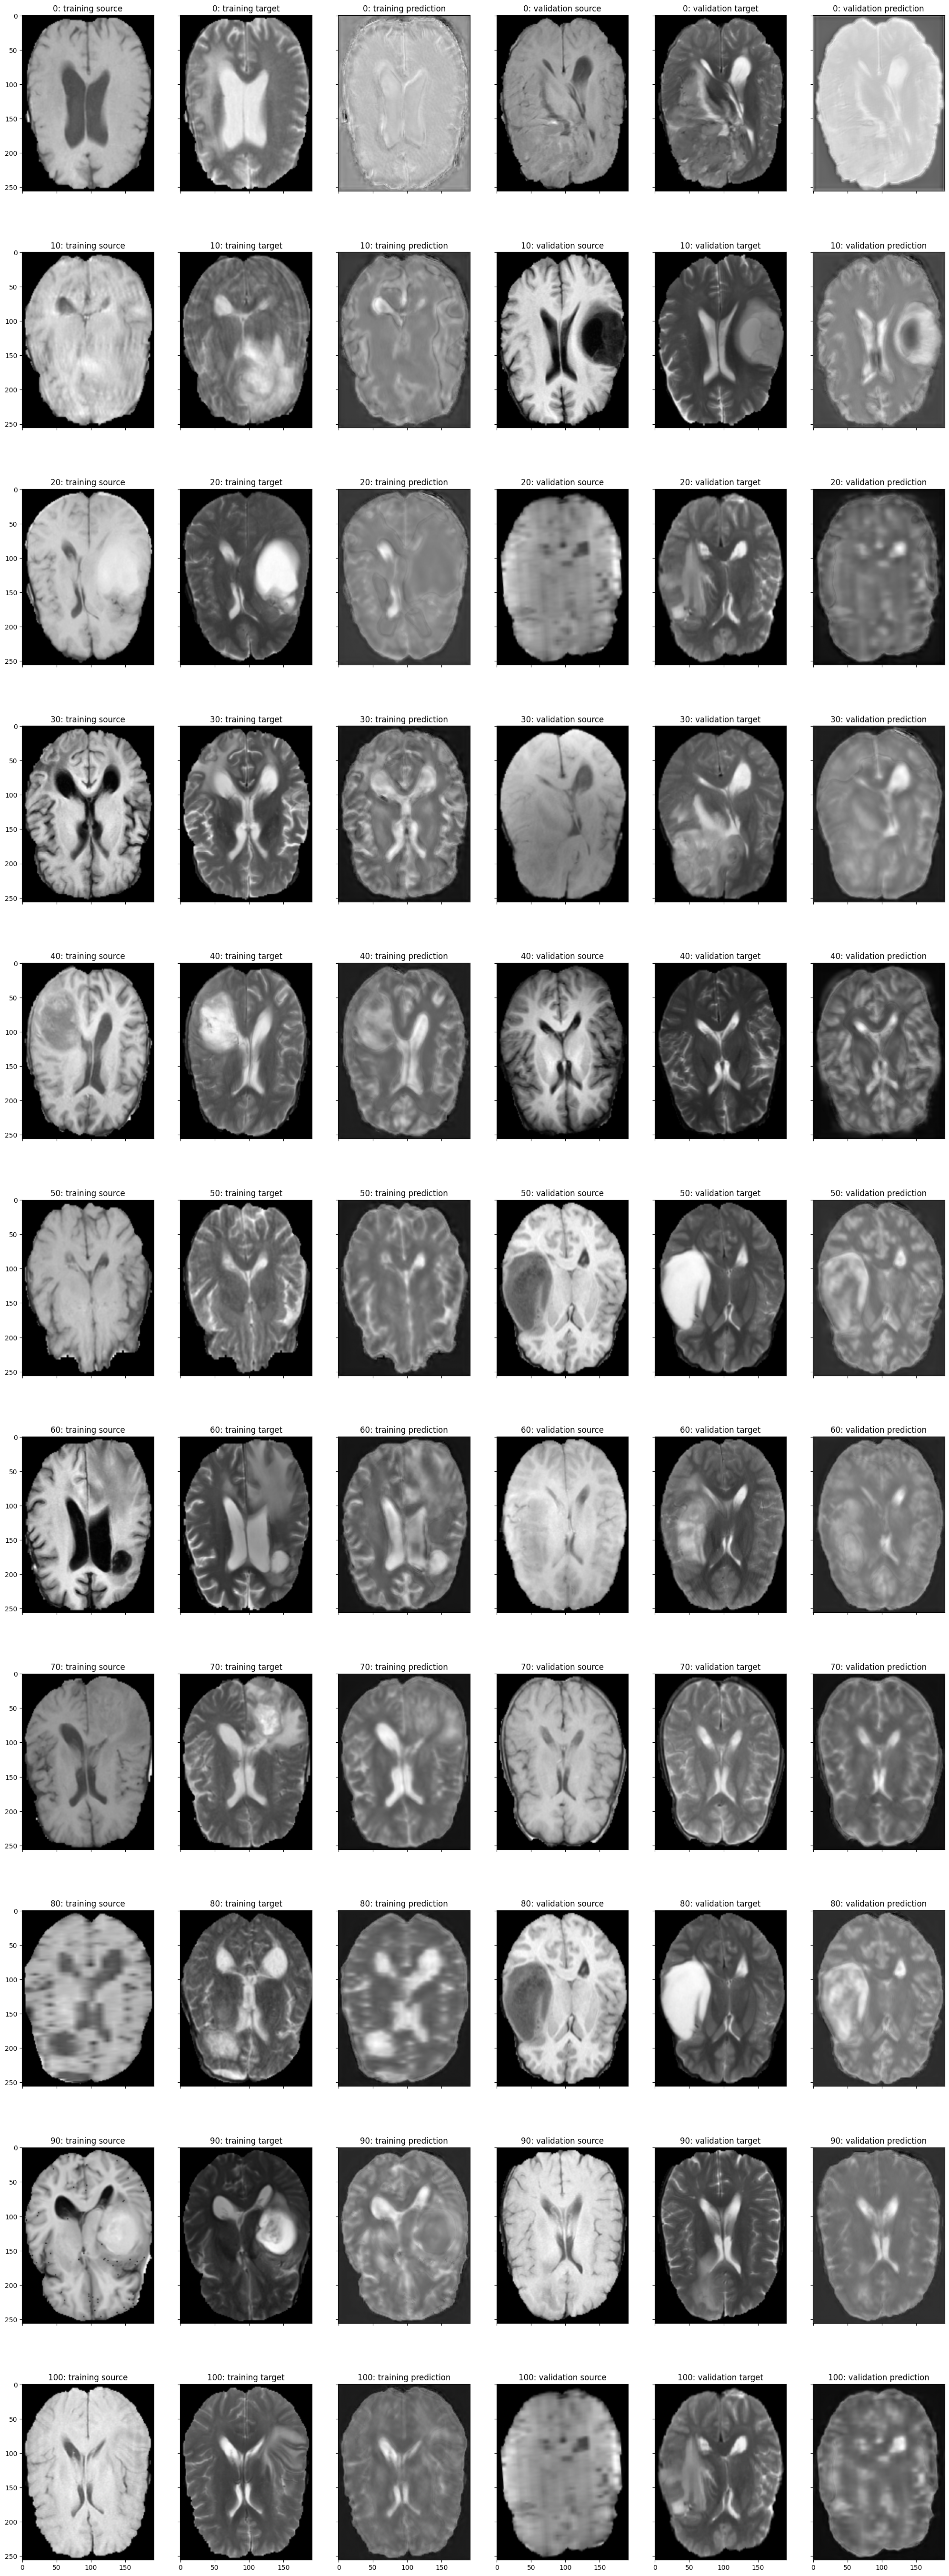

In [13]:
batch_size = 20

n_epochs = 101
every_epoch = n_epochs//10

device = 'cuda' if torch.cuda.is_available() else 'cpu'

fig, axs = plt.subplots(n_epochs//every_epoch + 1, 6, sharex=True, sharey=True,
                        figsize=(5*5, 7*n_epochs//every_epoch))

dataset_training = BrainsDataset()

# Split training dataset into 80% training images and 20% validation images
indices = list(range(len(dataset_training)))
split_index = int(len(dataset_training) * 0.8)
sampler_training = SubsetRandomSampler(indices[:split_index])
sampler_validate = SubsetRandomSampler(indices[split_index:])

loader_training = DataLoader(dataset=dataset_training,
                             batch_size=batch_size,
                             sampler=sampler_training,
                             drop_last=True)

loader_validate = DataLoader(dataset=dataset_training,
                             batch_size=batch_size,
                             sampler=sampler_validate,
                             drop_last=True)

# Initialize U-Net
unet = UNet().to(device)
unet.weight_init(mean=0.0, std=0.02)

loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(unet.parameters(), lr=0.0001)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=(9*n_epochs)//10, gamma=0.1)

losses_training = []
losses_validate = []

for epoch in range(n_epochs):

    # Scheduler will adapt the learning rate once the step count reaches threshold
    scheduler.step()

    ########################################
    #               TRAINING               #
    ########################################

    sum_loss = 0

    # Parameters must be trainable
    unet.train(True)
    with torch.set_grad_enabled(True):

        for batch in loader_training:
            source_image = batch['t1'].to(device)
            target_image = batch['t2'].to(device)
            optimizer.zero_grad()
            predicted_image = unet(source_image)
            loss = loss_fn(predicted_image,target_image)
            loss.backward()
            optimizer.step()


            sum_loss += loss.item()

        losses_training.append(sum_loss / len(loader_training))

    if epoch % every_epoch == 0:
        axs = visualize_images(axs, source_image,target_image, predicted_image, True, epoch, every_epoch)


    ########################################
    #              VALIDATION              #
    ########################################

    sum_loss = 0

    # Parameters must not be trainable
    unet.train(False)
    with torch.set_grad_enabled(False):

        # main loop to process all validation samples (packed into batches)
        for batch in loader_validate:
            source_image = batch['t1'].to(device)

            target_image = batch['t2'].to(device)

            predicted_image = unet(source_image)
            loss = loss_fn(predicted_image, target_image)

            sum_loss += loss.item()

        losses_validate.append(sum_loss / len(loader_validate))

    if epoch % every_epoch == 0:
        print('Epoch ' + str(epoch) + ' - Training Loss: ' + str(losses_training[-1]) +
              ', Validation Loss: ' + str(losses_validate[-1]))
        axs = visualize_images(axs, source_image,target_image, predicted_image, False, epoch, every_epoch)

print('\n')

# Training

| Epoch | Training loss | Validation loss |
|---|---|---|
| 0 | 0.2865 | 0.2784 |
| 10 | 0.0388 | 0.0333 |
| 20 | 0.0176 | 0.0140 |
| 30 | 0.0138 | 0.0125 |
| 50 | 0.0123 | 0.0128 |
| 100 | **0.0104** | **0.0095** |

*   MSE fell about 96 percent for both validation and training. About 90 percent of the total training-loss reduction happened within 10 epochs.

*   At epoch 0, it can be seen that the output us an almost featureless grey image. By epoch 20 the main structures and ventricles appear. At epoch 100 the network reproduces the T2 contrast but with softer edges and less fine detail than the real T2 image.

The network learned the T1 -> T2 translation. It reproduces the global contrast well but is weak in fine detail.


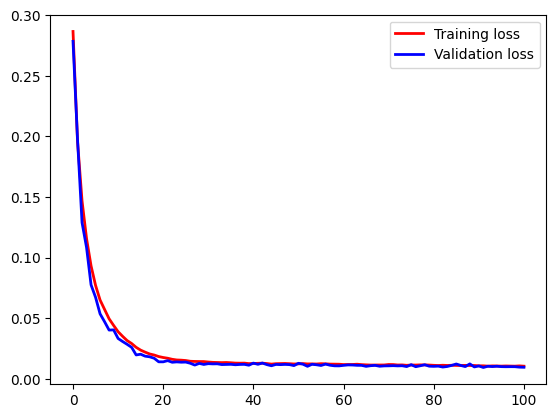

In [14]:
# Plot training and validation loss
plt.figure()
plt.plot(losses_training, 'r-', linewidth=2)
plt.plot(losses_validate, 'b-', linewidth=2)
plt.legend(('Training loss', 'Validation loss'));



1.   Both curves fall steeply during the first 20 epochs and faltten at about 0.01 from epoch 40 onwards
2.   There is no gap between training and validation curve, it shows there is no overfitting. In the end the validation loss is less than training loss. It is plausible because the weights are still improving and small validation set makes the curve noisy.
3.   Training and validation loss are equally high, the remaining error is probably not caused by overfitting. The small network and the MSE loss, which averages over plausible outputs and favours smooth images, are the more likely limits.

The training looks stable and converges to a plateau.


In [15]:
dataset_testing = BrainsDataset(mode='test')
loader_testing = DataLoader(dataset=dataset_testing, batch_size=1, shuffle=False)

losses_testing = []
sum_loss = 0
unet.train(False)
with torch.set_grad_enabled(False):
  for batch in loader_testing:
    source_image = batch['t1'].to(device)
    target_image = batch['t2'].to(device)
    predicted_image = unet(source_image)
    loss = loss_fn(predicted_image, target_image)
    losses_testing.append(loss.item())
    sum_loss += loss.item()

print('Testing Loss: ' + str(sum_loss / len(loader_testing)))

Testing Loss: 0.01021364303305745


**Goal:** generate T2-weighted brain MR images from T1-weighted images with a 2D U-Net.

| Stage | Result |
|---|---|
| Data | paired, aligned T1/T2 slices, scaled to [0, 1], size 256 x 192 |
| Model | U-Net with 20-40-80 feature maps, 2 skip connections, 257,381 parameters |
| Training | MSE loss, Adam (lr 1e-4), step scheduler (x 0.1 at ~90 % of training), 101 epochs, batch size 20 |
| Training result | loss 0.2865 -> 0.0104 (-96 %) |
| Validation result | loss 0.2784 -> 0.0095, no overfitting |
| **Test result** | **MSE 0.0102** (RMSE about 0.10, PSNR about 19.9 dB) |

